## Exploring Stochastic Subspace Descent

In [1]:
import jax
import jax.numpy as jnp
from scipy import linalg
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import line_search
from scipy.optimize import root
from scipy.optimize import rosen, rosen_der
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.animation import FuncAnimation

### Algorithm: 
$$\vec{x}_{k+1} = \vec{x}_k + \alpha \textbf{P}_k \textbf{P}_k^T \nabla f(\vec{x_k})$$
$P \in R^{d \times l}, l \leq d$.  Note $0 < \alpha < 2 \textit{l}/(d\lambda)$

Haar Distributed random matrix: 
$$ \textbf{P} = \sqrt{d \textit{l}} \textbf{Q} \textbf{I}_{d \times l} \in \mathbb{R}^{d \times l}$$

Convergence rate:   
per Corollary 2.3 from 2019 ssd paper, convergence rate under strong convexity should be linear, where 
$$\mathbb{E} f(x_k) - f* \leq \beta^k (f(x_k) - f*), \quad \beta = 1 - l\gamma / d\lambda$$
where $\gamma$ is the smallest eigenvalue of A, and $\lambda$ is the lipschitz constant of the first derivative. 

Note from 5/15/2026 meeting: finding the $\lambda$ may not always be accessible for all functions. So we implement line search in the for-loop for each alpha, and that should yield better results than guessing. 

Think about what could change about the algorithm for nonlinear least squares function of the form
$$ f(\textbf{x}) = \frac{1}{2} \sum_i r_i(\textbf{x})^2 = \frac{1}{2} ||r_i(\textbf{x})||^2$$
where $\nabla f = J^T \textbf{r}$

### Methodology
Need to: 
* define f such that it satisfies all assumptions outline in (D. Kozak et al.)
* define P
* iterative SSD algorithm with input f, P. Output parameters $\textbf{x}^*$ and plot loss function and convergence. 

Then compare results with other methods: 
- with line search: newton, BFGS(quasi-newton)
- without line search: block coordinate descent

### Objective Functions: 
Quadratic: strong convex
$$f(x) = \frac{1}{2} x^T A x - b^T x $$
* lambda is the spectral norm of A, so alpha can be determined
* gamma is the smallest eigenvalue of A (Rayleigh Quotient proof), so beta can be determined
* exact solution can be determined using linalg.solve

Rosenbrock: non-convex
$$f(x) = \sum_{i=1}^{d-1} [100 (x_{i-1} - x_i^2)^2 + (x_i - 1)^2 ]$$
* $\textbf{x}^* = (1, 1, ..., 1), f^* = 0
* need line search for alpha

Sphere Function: convex
$$f(\textbf{x}) = \sum_{i=1}^n x_i^2$$
* global minimum at 0
* $\lambda = 2$ and $\gamma = 2$

Ackley Function: non-convex
$$f(x_1, x_2) = -20 exp[-0.2\sqrt{0.5(x^2 + y^2)}] - exp[0.5(\cos 2 \pi x + \cos 2 \pi y) ] + e + 20$$
* global minimum at 0

In [16]:
#input alpha and l, independent variables
#0 < alpha < 2l/(d*lambda). Why?

def ssd(x, l, f, dim, alpha=None, max_iter=200):
    '''
    followed algorithm 2.1:
    1: Inputs: α, l. step size, subspace rank
    2: Initialize: x0 . arbitrary initialization
    3: for k = 1, 2, . . . do
    4: Generate P_k
    5: Apply recursion
    '''

    fx = []
    x_history = [np.array(x)]
    gradientFcn = jax.jit(jax.grad(f))
    for n in range(max_iter):
        #generate P using haar distribution (not necessary)
        Z = np.random.default_rng().standard_normal((dim, l)) # 
        Q, R = linalg.qr(Z, mode='economic') #economic mode for finding the QR so it's not a full square matrix
        #lambda step is optional, only required for Haar. 
        # Lambda = np.diag(np.sign(np.diag(R))) # R_ii > 0, ensure unique QR fact. 
        P = np.sqrt(dim / l) * Q 

        #recurse
        grad = gradientFcn(x)
        y = P.T @ grad
        step = P @ y
        if alpha is None:
            p_k = - step
            result = line_search(
                    lambda x: float(f(jnp.array(x))),
                    lambda x: np.array(gradientFcn(jnp.array(x))),
                    np.array(x),
                    p_k,
                )
            alpha = result[0]
            x = x + alpha * p_k
        else:
            x = x - alpha* step
        
        #plug x into function
        fx.append(float(f(jnp.array(x))))
        x_history.append(np.array(x))

    return fx, x_history

#### Outline the function for objective functions: 

considerations: 
- objective function defined as f, the lambda function.
- if a function has a known lambda, use it. Otherwise do line search on alpha. 
- if a function has a known solution, use it. Otherwise solve using scipy.linalg.solve
- find gamma.
- plot the convergence against strong convex, convex, and non-convex lines.
- build a class? yes

```
def eval(objective function, known lambda=false, f_exact=false, x, l, max_iter=)
    find alpha, lambda, beta, f_exact
    evaluate using ssd()
    plot
    return None
```

f (exact) = 0
final f = 0.49439913034439087
x history = [0.947667   0.9785799  0.33229148 0.46866846 0.5698887  0.16550303] [0.94895047 0.89925456 0.8088014  0.6555968  0.42997772 0.18144679]


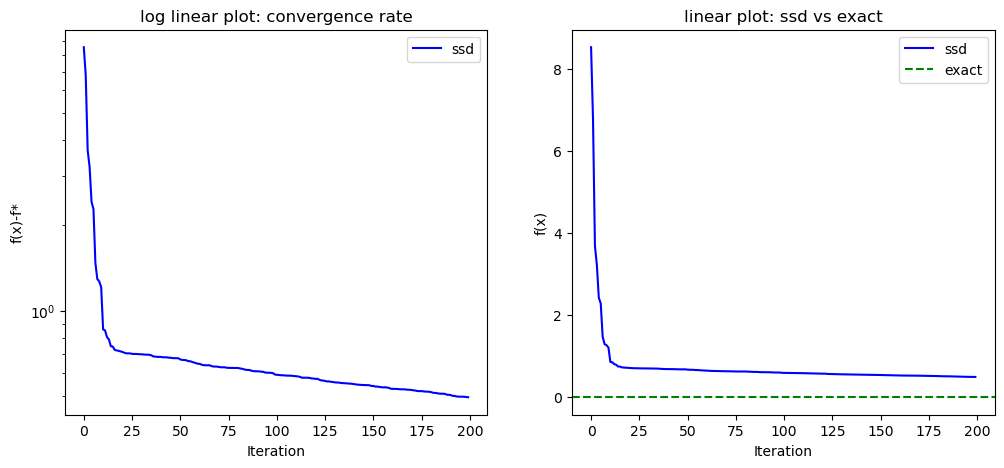

In [33]:
# conv = "strong convex" or "convex" or "nonconvex"
# sol_np needs to be a numpy array
def eval(ObjFnc, x, l, lam=None, sol_np=None, conv='', gamma=None):

    dim = x.shape[0]
    if sol_np is not None:
        f_exact = sol_np
    else:
        #solve a general function. Only solve quadratic rn
        x_exact = linalg.solve(A,b, assume_a = 'pos')
        f_exact = f(x_exact)

    if lam:
        alpha = l /(dim*lam)
        result, x_history = ssd(x, l, ObjFnc, dim, alpha)
    else:
        result, x_history = ssd(x, l, ObjFnc, dim)
        
    print("f (exact) =", f_exact)
    print("final f =", result[-1])
    print("x history =", x_history[0], x_history[-1])
    
    #plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    ax1.set_title('log linear plot: convergence rate')
    ax1.semilogy(result - f_exact, color='b', label='ssd')
    
    if conv == "strong convex" or conv == "convex":
        initial_gap = result[0] - f_exact
        k = np.arange(1, len(result) + 1)
        if conv == "strong convex":
            beta = 1 - (l * gamma)/ (dim*lam)
            ax1.semilogy(beta**k * initial_gap, color='r', ls='dashed', label='strong-conv conv. rate (linear)')
        else:
            sublinear_rate = sublinear_rate = initial_gap / k
            ax1.semilogy(sublinear_rate, color='g', ls='dashed', label='convex conv. rate (sublinear)')
            
    ax1.set_xlabel("Iteration")
    ax1.set_ylabel("f(x)-f*")
    ax1.legend()
    
    ax2.set_title('linear plot: ssd vs exact')
    ax2.plot(result, color='b', label='ssd')
    ax2.axhline(f_exact, color='g', label='exact', ls='dashed')
    ax2.set_xlabel("Iteration")
    ax2.set_ylabel("f(x)")
    ax2.legend()
    
    plt.show()

    # #AI wrote this after prompting for visualization
    # def animate_3d(f, x_history, result, f_exact):
    #     fig = plt.figure(figsize=(10, 8))
    #     ax = fig.add_subplot(111, projection='3d')
        
    #     # surface mesh
    #     xs = np.linspace(min(h[0] for h in x_history) - 1,
    #                  max(h[0] for h in x_history) + 1, 100)
    #     ys = np.linspace(min(h[1] for h in x_history) - 1,
    #                  max(h[1] for h in x_history) + 1, 100)
    #     X, Y = np.meshgrid(xs, ys)
    #     Z = np.array([[float(f(jnp.array([xi, yi]))) for xi in xs] for yi in ys])
        
    #     ax.plot_surface(X, Y, Z, cmap='viridis', alpha=0.6, edgecolor='none')
        
    #     # initialize path and point
    #     path_line, = ax.plot([], [], [], 'r-', linewidth=2)
    #     current_pt, = ax.plot([], [], [], 'r*', markersize=15)
    #     title = ax.set_title('')
    #     ax.set_xlabel('x')
    #     ax.set_ylabel('y')
    #     ax.set_zlabel('f(x,y)')
    
    #     def update(frame):
    #             hx = [h[0] for h in x_history[:frame+1]]
    #             hy = [h[1] for h in x_history[:frame+1]]
    #             hz = [float(f(jnp.array([h[0], h[1]]))) for h in x_history[:frame+1]]
    #             path_line.set_data(hx, hy)
    #             path_line.set_3d_properties(hz)
    #             current_pt.set_data([x_history[frame][0]], [x_history[frame][1]])
    #             current_pt.set_3d_properties([hz[-1]])
    #             ax.view_init(elev=30, azim=frame * 2)  # rotate 2 degrees per frame
    #             title.set_text(f'Iteration {frame}, f = {hz[-1]:.4f}')
    #             return path_line, current_pt, title
    
    #     ani = FuncAnimation(fig, update, frames=len(x_history),
    #                         interval=150, blit=False)
    #     ani.save("ssd_3d.gif", writer="pillow", fps=10)
    #     plt.show()
    
    # animate_3d(ObjFnc, x_history, result, f_exact)

    return None

'''testing'''
key = jax.random.PRNGKey(0)
x = jax.random.uniform(key, shape=(6))

# # evaluate quadratic
# key = jax.random.PRNGKey(0)
# A = np.random.randn(4,4)
# A = A@A.T + 0.1 * np.eye(4)#A needs to be positive definite
# print(A)
# b = np.array([2, 4, 1, 3])
# quad = lambda x: (0.5) * x.T @ A @ x - b.T @ x
# eval(quad, x, 2, lam = linalg.norm(A, ord=2), conv = "strong convex")

#non-convex function: Rosenbrock. Need to look into non-convex function convergence. 
rosen = lambda x: sum(100*(x[i+1] - x[i]**2)**2 + (1 - x[i])**2 
                  for i in range(len(x)-1))
eval(rosen, x, 2, sol_np=np.array(0))

# # convex function: sphere
# sphere = lambda x: sum(x[i]**2 for i in range(len(x)-1))
# #find lambda and gamma by hand
# eval(sphere, x, 2, lam=2, gamma=2, sol_np=np.array(0), conv="convex")

# #ackley function: non-convex
# ackley = lambda x: -20 * jnp.exp(-0.2 * jnp.sqrt(np.mean(x**2))) - jnp.exp(np.mean(jnp.cos(2 * np.pi * x))) + 20 + jnp.e
# eval(ackley, x, 2, sol_np=np.array(0), conv="nonconvex")
#ackley function seems to be stuck in the local min and doesn't converge to global min, is that to be expected or not? 

In [173]:
#newton's method w/o line search: alpha = 1
def newton(x0, f, max_iter=100, tol=1e-6):
    fx = []
    x = jnp.array(x0, dtype=float)
    for n in range(max_iter):
        grad = jax.grad(f)(x)

        #test tolerance
        if linalg.norm(grad) < tol:
            print (f" f (without line search) converged at iteration {n}")
            break

        H = jax.hessian(f)(x)
        p = linalg.solve(H, -grad)
        x = x + p
        fx.append(f(x))
    return fx

result_n = newton(np.random.rand(4).tolist(), f)

 f (without line search) converged at iteration 1


In [174]:
#newton's method with line search: 
def newton_ls(x0, f, max_iter=100, tol=1e-6):
    fx = []
    x = jnp.array(x0, dtype=float)
    grad_fn = lambda x: np.array(jax.grad(f)(jnp.array(x)))
    f_np = lambda x: float(f(jnp.array(x)))
    
    for n in range(max_iter):
        grad = jax.grad(f)(x)

        #test tolerance
        if linalg.norm(grad) < tol:
            print (f" f (with line search) converged at iteration {n}")
            break

        H = jax.hessian(f)(x)
        p = linalg.solve(H, -grad)

        #wolfe condition line search
        #scipy.optimize.line_search uses numpy array and functions. 
        alpha = line_search(f_np, grad_fn, np.array(x), np.array(p))
        
        x = x + alpha[0] * p
        fx.append(f(x))
    return fx

result_nls = newton_ls(np.random.rand(4).tolist(), f)

 f (with line search) converged at iteration 1


In [ ]:
#gradient descent
def grad_desc()